# M02 Overview | Splitting Prepare and Convert Apart: Where Observers Come From and What They Become

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m02_observer_fakequant/00_overview.ipynb)

M01 used `prepare_pt2e` and `convert_pt2e` as black boxes: one inserts observers, the other replaces observers with q/dq.
This chapter opens both boxes and redoes them by hand, without calling them, to show that only a few graph-editing actions are inside.
The next three notebooks (M02-1 to M02-3) verify each piece hands-on.

This chapter covers only the observer itself and the editing mechanics; **where** observers go is decided by the Quantizer, which is the topic of the next chapter, M03.

In [1]:
#| include: false
# When running on Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # let the notebook import this course's common/
    os.chdir(f"{repo}/en/m02_observer_fakequant")

In [2]:
#| echo: false
import copy

import torch

from common.graph_utils import observer_nodes
from common.models import example_inputs, get_model
from common.pt2e import (
    MovingAverageMinMaxObserver,
    convert_pt2e,
    export_module,
    get_xnnpack_quantizer,
    prepare_pt2e,
    quiet,
)
from common.viz import draw_stages

quiet()
_ = torch.manual_seed(0)
QD = torch.ops.quantized_decomposed

## Why Split Them Apart

Writing your own quantizer (M03), understanding how BN gets folded (M04), and arranging the QAT training flow (M06) all require knowing what prepare and convert do to the graph.
Otherwise, when something goes wrong you can only guess: what is the observer actually computing? How does it appear in the graph? Where does the scale after convert come from?

This chapter answers three questions:

| Question | One-line answer | Verified hands-on in |
|---|---|---|
| What does an observer compute? | It records the numeric range and derives scale and zero point; different observers pick the range differently | M02-1 |
| How does an observer get into the graph? | Attach a submodule, insert a `call_module` node, and rewire the downstream | M02-2 |
| How does an observer become q/dq? | Take out the qparams, replace it with quantize and dequantize nodes, then precompute the int8 weight | M02-3 |

## An Example First: a Fully Hand-Made conv → relu

The same conv → relu as in M01, and the three stages look the same. The difference: **stages two and three here do not call `prepare_pt2e` or `convert_pt2e`**;
they are made by hand with the graph-editing code from M02-2 and M02-3 (the code is hidden here, only the results are shown). The first row is the export and the hand-inserted observers, the second row is the hand-replaced q/dq:

- **Hand-inserted observers**: one observer each on the input `x`, the conv weight, and the relu output (green boxes), with kinds following the XNNPACKQuantizer configuration.
- **Hand-replaced q/dq**: after calibration, each observer is replaced by a quantize → dequantize pair, with scale and zero point written on the node.

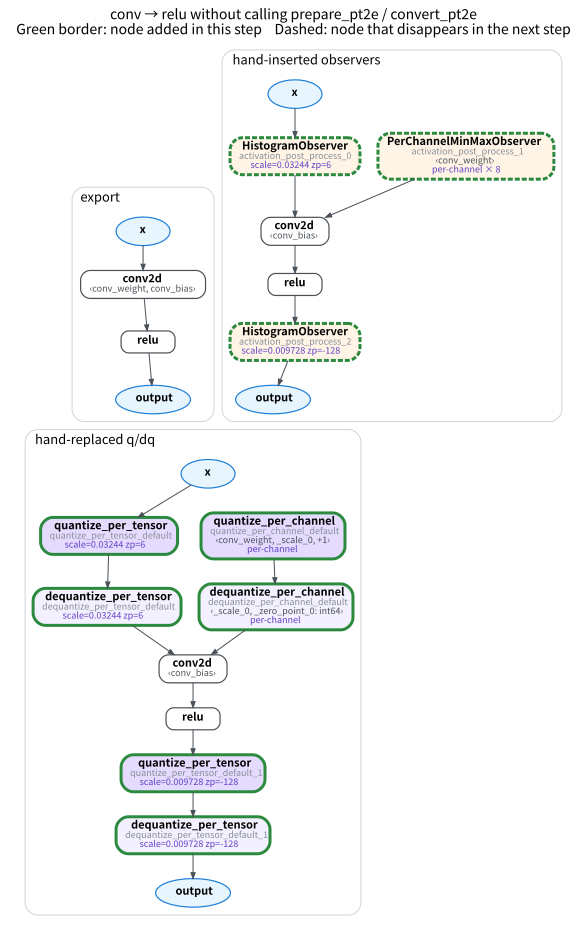

In [3]:
#| echo: false
def insert_after(gm, node, module, name):
    gm.add_submodule(name, module)
    with gm.graph.inserting_after(node):
        new = gm.graph.call_module(name, (node,))
    node.replace_all_uses_with(new, delete_user_cb=lambda user: user is not new)


def make(spec):
    kw = dict(dtype=spec.dtype, qscheme=spec.qscheme, quant_min=spec.quant_min, quant_max=spec.quant_max)
    if spec.ch_axis is not None:
        kw["ch_axis"] = spec.ch_axis
    return spec.observer_or_fake_quant_ctr.with_args(**kw)()


def to_qdq(gm):
    g = gm.graph
    for k, (node, obs) in enumerate(observer_nodes(gm)):
        s, z = obs.calculate_qparams()
        args = (obs.quant_min, obs.quant_max, obs.dtype)
        with g.inserting_before(node):
            if s.numel() > 1:
                gm.register_buffer(f"_scale_{k}", s)
                gm.register_buffer(f"_zero_point_{k}", z)
                sn, zn = g.get_attr(f"_scale_{k}"), g.get_attr(f"_zero_point_{k}")
                q = g.call_function(QD.quantize_per_channel.default, (node.args[0], sn, zn, obs.ch_axis, *args))
                dq = g.call_function(QD.dequantize_per_channel.default, (q, sn, zn, obs.ch_axis, *args))
            else:
                q = g.call_function(QD.quantize_per_tensor.default, (node.args[0], float(s), int(z), *args))
                dq = g.call_function(QD.dequantize_per_tensor.default, (q, float(s), int(z), *args))
        node.replace_all_uses_with(dq)
        g.erase_node(node)
        gm.delete_submodule(node.target)
    gm.recompile()
    return gm


def calibrate(gm):
    g = torch.Generator().manual_seed(0)
    with torch.no_grad():
        for _ in range(8):
            gm(torch.randn(4, 3, 16, 16, generator=g))


gm = export_module(get_model("conv_relu").eval(), example_inputs(4))
quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)
cfg = quantizer.global_config
assert cfg is not None and cfg.input_activation is not None and cfg.weight is not None
act_spec, weight_spec = cfg.input_activation, cfg.weight

by_hand = copy.deepcopy(gm)
nodes = {n.name: n for n in by_hand.graph.nodes}
for i, (name, spec) in enumerate([("x", act_spec), ("conv_weight", weight_spec), ("relu", act_spec)]):
    insert_after(by_hand, nodes[name], make(spec), f"activation_post_process_{i}")
by_hand.recompile()
calibrate(by_hand)
hand_prepared = copy.deepcopy(by_hand)
hand_converted = to_qdq(by_hand)
draw_stages([(gm, "export"), (hand_prepared, "hand-inserted observers"), (hand_converted, "hand-replaced q/dq")],
            title="conv → relu without calling prepare_pt2e / convert_pt2e")

Matching graphs are not enough; the numbers must match too. Hand the same exported graph to `prepare_pt2e`, calibrate, run `convert_pt2e`, and compare with the hand-made result:

In [4]:
api_prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
calibrate(api_prepared)
api_converted = convert_pt2e(copy.deepcopy(api_prepared))

x = torch.randn(4, 3, 16, 16)
with torch.no_grad():
    diff = float((api_converted(x) - hand_converted(x)).abs().max())
same_qparams = all(
    torch.equal(a.calculate_qparams()[0], b.calculate_qparams()[0])
    for (_, a), (_, b) in zip(observer_nodes(api_prepared), observer_nodes(hand_prepared))
)
print(f"Hand-inserted observers have the same scales as prepare_pt2e? {same_qparams}")
print(f"Max difference between hand-replaced q/dq and convert_pt2e outputs:{diff}")
assert same_qparams and diff == 0

Hand-inserted observers have the same scales as prepare_pt2e? True
Max difference between hand-replaced q/dq and convert_pt2e outputs:0.0


Exactly identical. The only difference is a graph detail: `convert_pt2e` also precomputes the weight's quantize and stores only int8 (part D of M02-3 adds this step).

## Definitions

### Observer: two methods

An **observer** is an `nn.Module`; only two methods matter:

- `forward(x)`: record the values of `x` (min/max, or a histogram), then return `x` **unchanged**. So a graph with observers inserted produces outputs bit-for-bit identical to the original.
- `calculate_qparams()`: derive the scale $s$ and zero point $z$ from the recorded range. The conversion formula is in the M01 overview.

Observers differ only in "how the range is chosen". The ones used in this chapter:

| observer | How the range is chosen |
|---|---|
| `MinMaxObserver` | The smallest and largest values seen; a single outlier widens the range permanently |
| `MovingAverageMinMaxObserver` | A moving average of each batch's min/max, so old outliers fade (Eq. 1) |
| `PerChannelMinMaxObserver` | Each channel's own min/max; the scale is a vector |
| `HistogramObserver` | Records a histogram and searches for a range that lowers the quantization error; in this project, the default XNNPACKQuantizer configuration uses it for activations in PTQ (a configuration choice, not a rule) |
| `PlaceholderObserver` | Records nothing, only marks the dtype of this edge; dynamic quantization uses it |

The moving-average update rule ($c$ is `averaging_constant`; the first batch takes that batch's value directly); $x_{\max}$ is analogous:

$$
x_{\min} \leftarrow x_{\min} + c\,\big(x_{\min}^{\text{batch}} - x_{\min}\big) \tag{1}
$$

In [5]:
obs = MovingAverageMinMaxObserver(averaging_constant=0.1, dtype=torch.int8)
batches = [torch.randn(1000) * a for a in (1.0, 10.0, 1.0)]
hand = batches[0].min()
for b in batches:
    obs(b)
for b in batches[1:]:
    hand = hand + 0.1 * (b.min() - hand)  # Eq. (1)
print(f"observer min_val = {float(obs.min_val):.4f}; Eq. (1) by hand = {float(hand):.4f}")
assert torch.allclose(obs.min_val, hand)

observer min_val = -6.0902; Eq. (1) by hand = -6.0902


### Prepare Inserts Observers: Who Decides the Positions

What `prepare_pt2e` does to insert an observer is the graph editing from M00-4: attach an observer submodule, insert a `call_module` node, and make the downstream consume it.
Which positions and which kind of observer are decided by the annotations that the Quantizer passed in leaves on the graph; `prepare_pt2e` itself does not know where to quantize.
In this chapter, hand insertion follows the positions and settings of XNNPACKQuantizer directly; how annotations are written and how a Quantizer decides positions is the topic of M03.

### `FakeQuantize`: an Observer Plus Quantize → Dequantize

The prepare for QAT (`prepare_qat_pt2e`) inserts not observers but **fake quant** modules. A `FakeQuantize` wraps an observer, and its forward does two things, each with a switch:

| Switch | What it does when on |
|---|---|
| `observer_enabled` | Use the inner observer to record the range and update scale and zero point |
| `fake_quant_enabled` | Use the current scale and zero point to do quantize → dequantize, outputting floats that carry quantization error |

An observer only peeks and never changes values; fake quant lets later layers see the quantization error, so QAT can learn to tolerate it. For why QAT can backpropagate through round, see the fake quantization article in the references.

### Steps of `convert_pt2e`

According to the torchao 0.18 source, `convert_pt2e` does the following in order:

| Order | Step | What it does |
|---|---|---|
| 1 | observer → q/dq | Take out $s$ and $z$ with `calculate_qparams()`, and replace each observer with quantize and dequantize nodes |
| 2 | `_fold_conv_bn_qat` | Fold away the conv + bn left in place during QAT training (M04, M06) |
| 3 | `DuplicateDQPass` | When one dequantize has multiple users, make a copy for each user so the backend can rewrite them one by one |
| 4 | `PortNodeMetaForQDQ` | Move metadata such as annotations onto the q/dq nodes |
| 5 | `constant_fold` | The weight's quantize input is a constant; precompute it and store only int8 |

Because step 1 only calls `calculate_qparams()`, and `FakeQuantize` also has this method, the QAT graph takes the same path.
M02-3 does steps 1, 3, and 5 by hand, and the result has exactly the same op composition and outputs as `convert_pt2e`.

## Summary and Chapter Map

- Prepare and convert are both just graph edits: prepare inserts `call_module` (the observer), and convert replaces it with `call_function` (q/dq) and folds away constants.
- There are many kinds of observer, differing only in "how the range is chosen"; which kind and where it goes is decided by the Quantizer (M03).
- An observer only records and never changes values; fake quant does change values; the two behaviors have separate switches.

| notebook | Question it answers |
|---|---|
| [M02-1 Observer Zoo](01_observer_zoo.ipynb) | symmetric vs. affine, how each observer chooses a range, `ch_axis` for per-channel, which one real quantizers use |
| [M02-2 Insert Observers and Fake Quant by Hand](02_manual_insert.ipynb) | Insert observers without a Quantizer, replace them with FakeQuantize, the two switches |
| [M02-3 Do convert_pt2e by Hand](03_observer_to_qdq.ipynb) | observer → q/dq, `DuplicateDQPass`, constant folding of the weight |

What this chapter deliberately skips: who decides observer positions and how to write your own Quantizer (M03); how BN is folded into conv (M04);
when QAT flips the switches (M06); how a Q/DQ graph becomes integer kernels (M07 onward).

## References

- torchao 0.18 source:
  [`quantize_pt2e.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/quantize_pt2e.py) (convert steps),
  [`convert.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/convert.py) (observer → q/dq),
  [`observer.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/observer.py),
  [`fake_quantize.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/fake_quantize.py),
  [`duplicate_dq_pass.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/quantizer/duplicate_dq_pass.py)
- Official PyTorch tutorials: [PyTorch 2 Export Post Training Quantization](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quant_ptq.html),
  [How to Write a Quantizer for PyTorch 2 Export Quantization](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quantizer.html)
- [Some Basic Concepts of PyTorch FX Graph / Node](https://bobondemon.github.io/2025/07/29/%E7%AD%86%E8%A8%98-PyTorch-FX-%E7%9A%84-Graph-Node-%E4%B8%80%E4%BA%9B%E5%9F%BA%E7%A4%8E%E6%A6%82%E5%BF%B5/) (in Chinese): the node and graph operations used for graph editing
- [Understanding Fake Quantization in Quantization Aware Training](https://bobondemon.github.io/2022/11/19/%E6%90%9E%E6%87%82-Quantization-Aware-Training-%E4%B8%AD%E7%9A%84-Fake-Quantization/) (in Chinese): why fake quant can backpropagate
- [Quantization Error (Case without Clipping)](https://bobondemon.github.io/2023/10/28/Quantization-Error-Case-without-Clipping/), [Quantization Error (Case with Clipping)](https://bobondemon.github.io/2023/11/04/Quantization-Error-Case-with-Clipping/): quantization error splits into a discretization term and a clipping term, and choosing a larger or smaller range is a trade-off between them; this is the way to understand why M02-1's `HistogramObserver` does not simply use min/max